<a href="https://colab.research.google.com/github/nabillahumi/S5-Mesin_Learning/blob/main/Jobsheet9%20PBL/Praktikum%202%20(JS9).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#Langkah 1: Load dan Siapkan Dataset (cafes.csv & reviews.csv)

In [2]:
# Load dan siapkan data dari file CSV
import numpy as np
import pandas as pd

cafes = pd.read_csv('cafes.csv')
reviews = pd.read_csv('reviews.csv')

# Agregasi data reviews per kafe
cafe_reviews = reviews.groupby('cafe_id').agg({
    'rating': 'mean',
    'likes': 'sum',
    'review_id': 'count'
}).reset_index()

cafe_reviews.rename(columns={
    'rating': 'avg_review_rating',
    'likes': 'total_likes',
    'review_id': 'total_reviews_dataset'
}, inplace=True)

# Gabungkan dataset cafes dan reviews
data = pd.merge(cafes, cafe_reviews, on='cafe_id', how='inner')

# Membuat label kategori target (misal: 'Tinggi' jika rating >= 4.7, selain itu 'Cukup')
data['kategori_rating'] = data['rating'].apply(lambda x: 'Tinggi' if x >= 4.7 else 'Cukup')

# Memilih fitur (X) dan target (y)
X = data[['review_count', 'total_likes']].values
y = data['kategori_rating'].values

print("Ukuran fitur X:", X.shape)
print("Ukuran target y:", y.shape)

Ukuran fitur X: (94, 2)
Ukuran target y: (94,)


#Langkah 2: Membuat DataFrame (Opsional)

In [3]:
# Reshape label y menjadi 2D untuk digabungkan ke DataFrame
y_new = y.reshape(len(y), 1)

# Gabungkan fitur X dan label y
data_array = np.concatenate((X, y_new), axis=1)

# Definisikan nama kolom
nama_kolom = ['Fitur 1 (Review Count)', 'Fitur 2 (Total Likes)', 'Label']

# Buat DataFrame
df = pd.DataFrame(data_array, columns=nama_kolom)
df.head()

,Fitur 1 (Review Count),Fitur 2 (Total Likes),Label
0,528,0,Tinggi
1,141,0,Tinggi
2,1772,0,Cukup
3,701,0,Cukup
4,686,0,Cukup


#Langkah 3: Labeling (Mapping Kategori)

In [4]:
# Definisikan nama label baru
labels = {
    'Tinggi': 'Kelas A',
    'Cukup': 'Kelas B'
}

# Salin DataFrame dan lakukan mapping
df_label = df.copy()
df_label['Label'] = df_label['Label'].map(labels)

df_label.head()

,Fitur 1 (Review Count),Fitur 2 (Total Likes),Label
0,528,0,Kelas A
1,141,0,Kelas A
2,1772,0,Kelas B
3,701,0,Kelas B
4,686,0,Kelas B


#Langkah 4: Visualisasi Data

/tmp/ipykernel_1492/1453784541.py:11: FutureWarning: When grouping with a length-1 list-like, you will need to pass a length-1 tuple to get_group in a future version of pandas. Pass `(name,)` instead of `name` to silence this warning.
  class_a = gb.get_group('Kelas A')
/tmp/ipykernel_1492/1453784541.py:12: FutureWarning: When grouping with a length-1 list-like, you will need to pass a length-1 tuple to get_group in a future version of pandas. Pass `(name,)` instead of `name` to silence this warning.
  class_b = gb.get_group('Kelas B')


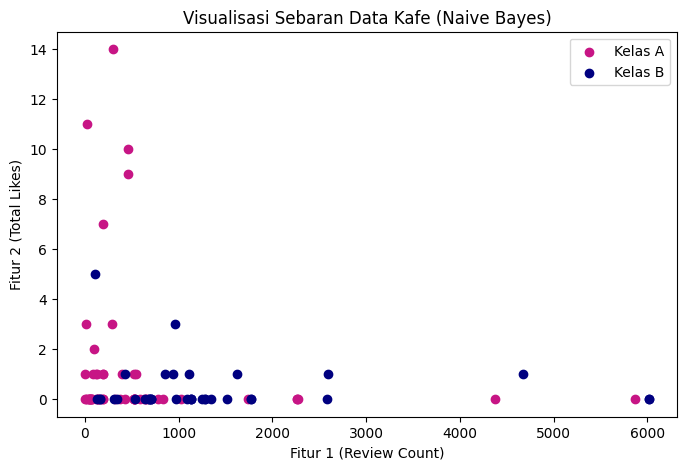

In [6]:
import matplotlib.pyplot as plt

# Definisikan warna untuk setiap kelas
colors = {
    'class_a': 'MediumVioletRed',
    'class_b': 'Navy'
}

# Kelompokkan label berdasarkan nama kelas
gb = df_label.groupby(['Label'])
class_a = gb.get_group('Kelas A')
class_b = gb.get_group('Kelas B')

# Plot scatter
plt.figure(figsize=(8, 5))
plt.scatter(pd.to_numeric(class_a['Fitur 1 (Review Count)']), pd.to_numeric(class_a['Fitur 2 (Total Likes)']), c=colors['class_a'], label='Kelas A')
plt.scatter(pd.to_numeric(class_b['Fitur 1 (Review Count)']), pd.to_numeric(class_b['Fitur 2 (Total Likes)']), c=colors['class_b'], label='Kelas B')
plt.xlabel('Fitur 1 (Review Count)')
plt.ylabel('Fitur 2 (Total Likes)')
plt.title('Visualisasi Sebaran Data Kafe (Naive Bayes)')
plt.legend()
plt.show()

#Langkah 5: Model Multinomial Naive Bayes

In [7]:
from sklearn.naive_bayes import MultinomialNB
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score

# Split data training dan testing (70% train, 30% test)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=30)

# Inisiasi objek MultinomialNB
mnb = MultinomialNB()

# Latih model
mnb.fit(X_train, y_train)

# Prediksi dan evaluasi data training
y_train_pred = mnb.predict(X_train)
acc_train = accuracy_score(y_train, y_train_pred)

# Prediksi dan evaluasi data testing
y_test_pred = mnb.predict(X_test)
acc_test = accuracy_score(y_test, y_test_pred)

print(f'Hasil akurasi data train (Multinomial): {acc_train:.4f}')
print(f'Hasil akurasi data test (Multinomial): {acc_test:.4f}')

Hasil akurasi data train (Multinomial): 0.6308
Hasil akurasi data test (Multinomial): 0.7931


#Langkah 6: Model Gaussian Naive Bayes

In [8]:
from sklearn.naive_bayes import GaussianNB

# Inisiasi objek GaussianNB
gnb = GaussianNB()

# Latih model menggunakan data training yang sama
gnb.fit(X_train, y_train)

# Prediksi dan evaluasi data training
y_train_pred_gnb = gnb.predict(X_train)
acc_train_gnb = accuracy_score(y_train, y_train_pred_gnb)

# Prediksi dan evaluasi data testing
y_test_pred_gnb = gnb.predict(X_test)
acc_test_gnb = accuracy_score(y_test, y_test_pred_gnb)

print(f'Hasil akurasi data train (Gaussian): {acc_train_gnb:.4f}')
print(f'Hasil akurasi data test (Gaussian): {acc_test_gnb:.4f}')

Hasil akurasi data train (Gaussian): 0.6308
Hasil akurasi data test (Gaussian): 0.7241
